In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import AllChem
import seaborn as sns
import scipy.stats  # Added for statistical testing

## Data

In [4]:
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"

# Replace with your seed SMILES
seed_smiles = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"  

input_file_1 = "../data/interim/molmim/unguided/molmmim_BCS-CN20332_QED_sim03_100p_100m.csv"
input_file_2 = "../data/interim/molmim/guided/v2/BCS-CN20332_QSARAIH_b1.csv"

In [5]:
df1 = pd.read_csv(input_file_1, sep=";")
df2 = pd.read_csv(input_file_2, sep=";")

In [6]:
df1.head()

,smiles,score,LogP,QED
0,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
1,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
2,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
3,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
4,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926


In [7]:
df2.head()

,valid_smiles,LogP,QED,AIH
0,C=Cn1cc(CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)cn1,2.18310,0.920099,228.39
1,CCn1ncc(CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)c1C1CC1,2.97990,0.868891,208.07
2,Cc1nocc1CNC(=O)[C@]1(C)CC(c2ccccc2)=NO1,2.18252,0.938444,181.60
3,Cn1nccc1CNC(=O)[C@]1(C)CC(c2ccccc2)=NO1,1.61960,0.932296,179.41
4,Cc1cccc(CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)c1,3.19452,0.942751,178.30


## Analysis

In [8]:
from molmim.by_scorer_new import MoleculeScorer
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=True,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=False,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)
#df1['AIH'] = scorer2.get_qsar_aih_predictions(df1['smiles'])
#df1['HSEC'] = scorer2.get_qsar_hsec_predictions(df1['smiles'])
#df2['AIH'] = scorer2.get_qsar_aih_predictions(df2['valid_smiles'])
#df2['HSEC'] = scorer2.get_qsar_hsec_predictions(df2['valid_smiles'])

In [10]:
results = scorer.score(df1['smiles'])
df1['AIH'] = results.norm_qsar_aih_scores
df1['HSEC'] = results.norm_qsar_hsec_scores

#~now scoring~#
#~Done scoring~#


In [11]:
results2 = scorer.score(df2['valid_smiles'])
df2['AIH'] = results2.norm_qsar_aih_scores
df2['HSEC'] = results2.norm_qsar_hsec_scores

#~now scoring~#
#~Done scoring~#


In [12]:
df2

,valid_smiles,LogP,QED,AIH,HSEC
0,C=Cn1cc(CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)cn1,2.18310,0.920099,0.506164,0.395309
1,CCn1ncc(CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)c1C1CC1,2.97990,0.868891,0.469218,0.369291
2,Cc1nocc1CNC(=O)[C@]1(C)CC(c2ccccc2)=NO1,2.18252,0.938444,0.421091,0.384418
3,Cn1nccc1CNC(=O)[C@]1(C)CC(c2ccccc2)=NO1,1.61960,0.932296,0.417109,0.352545
4,Cc1cccc(CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)c1,3.19452,0.942751,0.415091,0.339000
...,...,...,...,...,...
61,CN1CCC[C@](CNC(=O)[C@]2(C)CC(c3ccccc3)=NO2)(N(...,1.71190,0.870646,0.071291,0.105182
62,CC(C)(C)CNC(=O)N1C[C@H]2CC[C@@]2(CO)C1,1.44640,0.767250,0.068527,0.119055
63,CN(C)C(=O)CCNCC[C@]1(C)CC(=O)C(C)(C)O1,0.97110,0.730745,0.051982,0.072073
64,CC[C@](C)(CN)CN(C)[C@H](C)CCC(c1ccccc1)c1ccccc1,5.29400,0.628975,0.000000,0.044982


In [25]:
df1

,smiles,score,LogP,QED,AIH,HSEC
0,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
1,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
2,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
3,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
4,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
...,...,...,...,...,...,...
95,COC(=O)CCNC(=O)C1(n2cc(Br)ccc2=O)CCCCC1,0.786483,1.9495,0.786483,0.074636,0.166836
96,COC(=O)CCNC(=O)C1(n2cc(Br)ccc2=O)CCCCC1,0.786483,1.9495,0.786483,0.074636,0.166836
97,COC(=O)CCNC(=O)C1(C)CC(C)C1,0.711437,1.1019,0.711437,0.224200,0.207582
98,COC(=O)CCNC(=O)C1(C)CC(=O)C1,0.668842,0.0349,0.668842,0.176655,0.220218


<Figure size 1200x800 with 0 Axes>

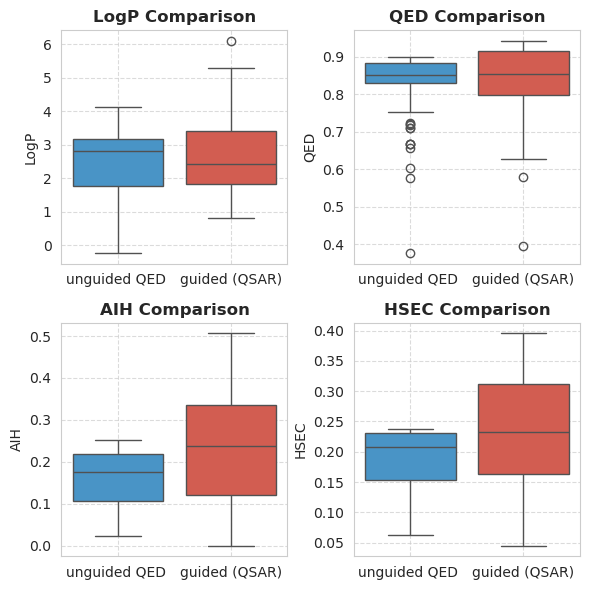

In [14]:
def create_comparison_boxplots(df1, df2, columns=['LogP', 'QED', 'AIH', 'HSEC'], name1 ='Dataset 1', name2 ='Dataset 2' ):
    # Set figure size and style
    plt.figure(figsize=(12, 8))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(6, 6))
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#e74c3c']
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot
        #sns.boxplot(x='Dataset', y=column, data=melted_df, palette=colors, ax=axes[i])
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, legend=False, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column} Comparison', fontweight='bold')
        axes[i].set_xlabel('')
        axes[i].grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()


create_comparison_boxplots(df1, df2, name1="unguided QED ", name2="guided (QSAR)")
